# Classificação de Corujas — V5: pesos fixos, busca automática e ajuste pós-treino

Esta é a última versão dos testes. Ela combina três ideias, sem pesos adaptativos durante o treino:

1. **Pesos fixos por candidato**, como na V4.
2. **Busca automática de `alpha` e `w_max`** com três candidatos, cada um treinado por até **100 épocas**.
3. **Ajuste pós-treino de vieses por classe** (`logits + bias`) na validação, para melhorar o equilíbrio entre acurácia e abrangência sem retreinar.

A função objetivo usada na seleção e no ajuste é:

\[
	ext{score} = 0,7 \cdot 	ext{F1 macro} + 0,3 \cdot 	ext{acurácia}
\]

O ajuste de vieses também impõe uma restrição: a acurácia na validação não pode cair mais de 1 ponto percentual.

**Nada é salvo no Google Drive.** O modelo e os resultados permanecem apenas na sessão do Colab.


## 1. Bibliotecas e configuração

O treino testa três configurações de pesos. Cada uma usa o mesmo split, a mesma arquitetura e o mesmo limite de 100 épocas, com early stopping.


In [1]:
%pip install -q numpy pandas matplotlib scikit-learn gdown

import sys
import time
import zipfile
from pathlib import Path

import gdown
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import tensorflow as tf
from IPython.display import display
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)
from sklearn.model_selection import train_test_split
from tensorflow.keras import callbacks, layers, models

SEMENTE = 42
TAMANHO_IMAGEM = (224, 224)
TAMANHO_LOTE = 32
EPOCAS = 100
PESO_F1 = 0.7
PESO_ACCURACY = 0.3
PESO_MINIMO = 0.15
CANDIDATOS = [
    (0.65, 2.5),
    (0.75, 3.0),
    (0.85, 3.5),
]

tf.keras.utils.set_random_seed(SEMENTE)

print('Python:', sys.version.split()[0])
print('TensorFlow:', tf.__version__)
print('Scikit-learn:', sklearn.__version__)
print('GPUs:', tf.config.list_physical_devices('GPU'))


Python: 3.13.16
TensorFlow: 2.21.0
Scikit-learn: 1.6.1
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Base de dados

A base é baixada para `/content/imgs` apenas se ainda não existir. Nenhum artefato é enviado ao Drive.


Downloading...
From (original): https://drive.google.com/uc?id=1fq87mnV4pG1PSV_qwWM3-IXlkWL4O6is
From (redirected): https://drive.google.com/uc?id=1fq87mnV4pG1PSV_qwWM3-IXlkWL4O6is&confirm=t&uuid=bf9f9872-20ef-47cf-bf18-49e182e202bc
To: /content/imgs.zip
100%|██████████| 985M/985M [00:30<00:00, 32.3MB/s]


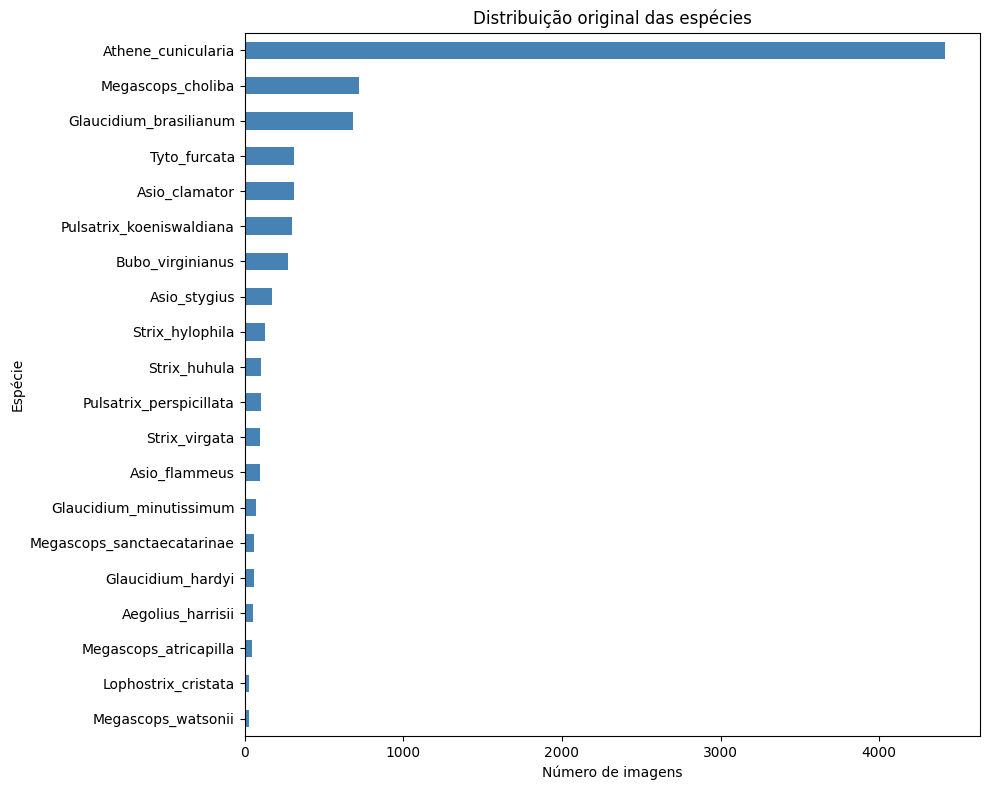

Classes: 20
Total de imagens: 8067
Megascops_watsonii              26
Lophostrix_cristata             27
Megascops_atricapilla           44
Aegolius_harrisii               55
Glaucidium_hardyi               57
Megascops_sanctaecatarinae      58
Glaucidium_minutissimum         74
Asio_flammeus                   96
Strix_virgata                   96
Pulsatrix_perspicillata        105
Strix_huhula                   106
Strix_hylophila                131
Asio_stygius                   175
Bubo_virginianus               271
Pulsatrix_koeniswaldiana       300
Asio_clamator                  310
Tyto_furcata                   312
Glaucidium_brasilianum         686
Megascops_choliba              723
Athene_cunicularia            4415


In [2]:
FILE_ID = '1fq87mnV4pG1PSV_qwWM3-IXlkWL4O6is'
DATA_DIR = Path('/content/imgs')
ZIP_PATH = Path('/content/imgs.zip')

if not DATA_DIR.is_dir():
    url = f'https://drive.google.com/uc?id={FILE_ID}'
    gdown.download(url, output=str(ZIP_PATH), quiet=False)
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall('/content')
    ZIP_PATH.unlink(missing_ok=True)

if not DATA_DIR.is_dir() and Path('/content/images').is_dir():
    Path('/content/images').rename(DATA_DIR)

if not DATA_DIR.is_dir():
    raise FileNotFoundError(f'Diretório não encontrado: {DATA_DIR}')

EXTENSOES_IMAGEM = {'.jpg', '.jpeg', '.png', '.bmp', '.gif'}
nomes_das_classes = sorted(
    p.name for p in DATA_DIR.iterdir()
    if p.is_dir() and not p.name.startswith(('.', '__'))
)

contagem = {
    classe: sum(
        p.is_file() and p.suffix.lower() in EXTENSOES_IMAGEM
        for p in (DATA_DIR / classe).iterdir()
    )
    for classe in nomes_das_classes
}

if len(nomes_das_classes) != 20:
    raise ValueError(f'Esperava 20 classes, encontrei {len(nomes_das_classes)}')
if min(contagem.values()) < 2:
    raise ValueError(f'Classes com menos de 2 imagens: {contagem}')

contagem_serie = pd.Series(contagem, dtype='int64').sort_values()
contagem_serie.plot.barh(figsize=(10, 8), color='steelblue')
plt.title('Distribuição original das espécies')
plt.xlabel('Número de imagens')
plt.ylabel('Espécie')
plt.tight_layout()
plt.show()

print('Classes:', len(nomes_das_classes))
print('Total de imagens:', int(contagem_serie.sum()))
print(contagem_serie.to_string())


## 3. Divisão, pipeline e pesos fixos

A divisão é a mesma das versões anteriores: 70% treino, 15% validação e 15% teste, estratificada e com semente 42. O teste é o mesmo da V2, V3 e V4.

Cada candidato tem pesos fixos calculados antes do treino:

\[
w_c = 	ext{clip}\left(\left(rac{N}{K n_c}
ight)^lpha,\ 0.15,\ w_{max}
ight)
\]

Depois, os pesos são normalizados para média ponderada 1. Não há atualização de pesos durante o treino.


In [3]:
caminhos = []
rotulos = []
for indice, classe in enumerate(nomes_das_classes):
    arquivos = sorted(
        p for p in (DATA_DIR / classe).iterdir()
        if p.is_file() and p.suffix.lower() in EXTENSOES_IMAGEM
    )
    caminhos.extend(str(p) for p in arquivos)
    rotulos.extend([indice] * len(arquivos))

caminhos = np.asarray(caminhos)
rotulos = np.asarray(rotulos, dtype=np.int32)
num_classes = len(nomes_das_classes)

caminhos_treino, caminhos_temp, rotulos_treino, rotulos_temp = train_test_split(
    caminhos, rotulos, test_size=0.30, random_state=SEMENTE, stratify=rotulos
)
caminhos_validacao, caminhos_teste, rotulos_validacao, rotulos_teste = train_test_split(
    caminhos_temp, rotulos_temp, test_size=0.50, random_state=SEMENTE, stratify=rotulos_temp
)

AUTOTUNE = tf.data.AUTOTUNE

def carregar_imagem(caminho, rotulo):
    bytes_imagem = tf.io.read_file(caminho)
    imagem = tf.io.decode_image(bytes_imagem, channels=3, expand_animations=False)
    imagem = tf.image.resize(imagem, TAMANHO_IMAGEM, antialias=True)
    imagem.set_shape((*TAMANHO_IMAGEM, 3))
    return imagem, rotulo

def criar_dataset(caminhos_conjunto, rotulos_conjunto, treinamento=False):
    ds = tf.data.Dataset.from_tensor_slices((caminhos_conjunto, rotulos_conjunto))
    ds = ds.map(carregar_imagem, num_parallel_calls=AUTOTUNE)
    if treinamento:
        ds = ds.shuffle(
            buffer_size=min(len(caminhos_conjunto), 4096),
            seed=SEMENTE,
            reshuffle_each_iteration=True,
        )
    return ds.batch(TAMANHO_LOTE).prefetch(AUTOTUNE)

dataset_treino = criar_dataset(caminhos_treino, rotulos_treino, treinamento=True)
dataset_validacao = criar_dataset(caminhos_validacao, rotulos_validacao)
dataset_teste = criar_dataset(caminhos_teste, rotulos_teste)

print('Treino:', len(caminhos_treino))
print('Validação:', len(caminhos_validacao))
print('Teste:', len(caminhos_teste))

contagem_treino = np.bincount(rotulos_treino, minlength=num_classes)

def calcular_pesos(contagens, alpha, w_max):
    N = int(contagens.sum())
    K = len(contagens)
    balanceados = N / (K * contagens)
    brutos = balanceados ** alpha
    limitados = np.clip(brutos, PESO_MINIMO, w_max)
    media = np.average(limitados, weights=contagens)
    pesos = limitados / media
    return {int(i): float(w) for i, w in enumerate(pesos)}, balanceados, pesos

print('Configurações que serão treinadas:')
for alpha, w_max in CANDIDATOS:
    _, _, pesos = calcular_pesos(contagem_treino, alpha, w_max)
    print(f'  alpha={alpha}, w_max={w_max} | min={pesos.min():.3f} max={pesos.max():.3f}')


Treino: 5646
Validação: 1210
Teste: 1211
Configurações que serão treinadas:
  alpha=0.65, w_max=2.5 | min=0.295 max=3.491
  alpha=0.75, w_max=3.0 | min=0.225 max=4.063
  alpha=0.85, w_max=3.5 | min=0.192 max=4.491


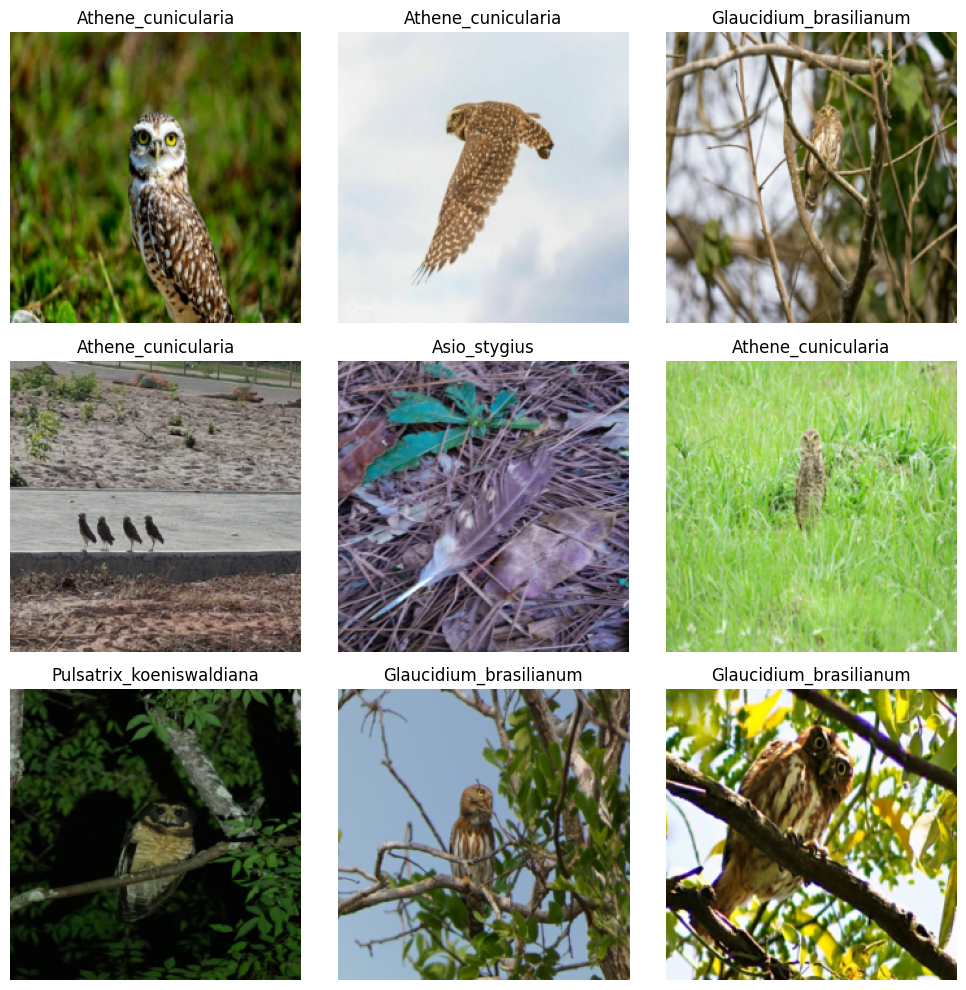

In [4]:
plt.figure(figsize=(10, 10))
for imagens, rotulos_lote in dataset_treino.take(1):
    for i in range(min(9, len(imagens))):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(imagens[i].numpy().astype('uint8'))
        plt.title(nomes_das_classes[int(rotulos_lote[i])])
        plt.axis('off')
plt.tight_layout()
plt.show()


## 4. Arquitetura própria

A arquitetura é a mesma da V4: quatro blocos convolucionais, duas convoluções 3×3 por bloco, BatchNorm, Dropout e GlobalAveragePooling. Ela não é alterada entre os candidatos.


In [5]:
def criar_cnn(num_classes):
    entradas = layers.Input(shape=(*TAMANHO_IMAGEM, 3), name='imagem')

    x = layers.RandomFlip('horizontal')(entradas)
    x = layers.RandomRotation(0.08, fill_mode='reflect')(x)
    x = layers.RandomZoom(0.10, fill_mode='reflect')(x)
    x = layers.RandomContrast(0.10)(x)
    x = layers.Rescaling(1.0 / 255.0, name='normalizacao')(x)

    for filtros, dropout in [(32, 0.10), (64, 0.15), (128, 0.20), (256, 0.25)]:
        for _ in range(2):
            x = layers.Conv2D(
                filtros, 3, padding='same', use_bias=False,
                kernel_initializer='he_normal'
            )(x)
            x = layers.BatchNormalization()(x)
            x = layers.Activation('relu')(x)
        x = layers.MaxPooling2D(2)(x)
        x = layers.Dropout(dropout)(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.30)(x)
    saidas = layers.Dense(num_classes, activation='softmax', name='especie')(x)
    return models.Model(entradas, saidas, name='cnn_corujas_v5')


modelo_exemplo = criar_cnn(num_classes)
modelo_exemplo.summary()


Model: "cnn_corujas_v5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagem (InputLayer)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ (None, 224, 224, 3)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalizacao (Rescaling)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 56, 56, 64)     │             

 Total params: 1,210,612 (4.62 MB)

 Trainable params: 1,208,692 (4.61 MB)

 Non-trainable params: 1,920 (7.50 KB)

## 5. Busca automática de `alpha` e `w_max`

Cada candidato é treinado por até 100 épocas. O callback calcula F1 macro e acurácia balanceada na validação e cria um score composto:

\[
	ext{score} = 0,7 \cdot 	ext{F1 macro} + 0,3 \cdot 	ext{acurácia}
\]

O `EarlyStopping` e o `ReduceLROnPlateau` usam esse score. O melhor peso de cada candidato é restaurado em memória; nenhum arquivo é salvo.


In [6]:
def avaliar_previsoes(y_real, probabilidades):
    previstos = np.argmax(probabilidades, axis=1)
    recall_classes = recall_score(
        y_real, previstos, labels=np.arange(num_classes),
        average=None, zero_division=0
    )
    return {
        'acuracia': float(accuracy_score(y_real, previstos)),
        'acuracia_balanceada': float(balanced_accuracy_score(y_real, previstos)),
        'precisao_macro': float(precision_score(y_real, previstos, average='macro', zero_division=0)),
        'recall_macro': float(recall_score(y_real, previstos, average='macro', zero_division=0)),
        'f1_macro': float(f1_score(y_real, previstos, average='macro', zero_division=0)),
        'zero_recall': int(np.sum(recall_classes == 0)),
        'recall_por_classe': recall_classes,
    }

def score_composto(metricas):
    return PESO_F1 * metricas['f1_macro'] + PESO_ACCURACY * metricas['acuracia']

def prever_metricas(modelo, dataset, rotulos_reais):
    probabilidades = modelo.predict(dataset, verbose=0)
    return avaliar_previsoes(rotulos_reais, probabilidades), probabilidades

def softmax_logits(logits, bias):
    z = logits + bias
    z = z - np.max(z, axis=1, keepdims=True)
    exp_z = np.exp(z)
    return exp_z / exp_z.sum(axis=1, keepdims=True)

class MetricasValidacao(callbacks.Callback):
    def __init__(self, dataset, rotulos):
        super().__init__()
        self.dataset = dataset
        self.rotulos = np.asarray(rotulos)
        self.f1_hist = []
        self.score_hist = []

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        probabilidades = self.model.predict(self.dataset, verbose=0)
        metricas = avaliar_previsoes(self.rotulos, probabilidades)
        score = score_composto(metricas)
        logs['val_f1_macro'] = metricas['f1_macro']
        logs['val_balanced_accuracy'] = metricas['acuracia_balanceada']
        logs['val_score'] = score
        self.f1_hist.append(metricas['f1_macro'])
        self.score_hist.append(score)


In [7]:
candidatos_resultados = []

for alpha, w_max in CANDIDATOS:
    print(f'\n=== Candidato alpha={alpha}, w_max={w_max} ===')
    pesos_das_classes, balanceados, pesos_finais = calcular_pesos(
        contagem_treino, alpha, w_max
    )

    tabela_pesos = pd.DataFrame({
        'Classe': nomes_das_classes,
        'Treino': contagem_treino,
        'Peso balanceado': balanceados,
        'Peso final': pesos_finais,
    }).sort_values('Peso final', ascending=False)
    display(tabela_pesos.round(3))

    tf.keras.utils.set_random_seed(SEMENTE)
    modelo = criar_cnn(num_classes)
    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy'],
    )

    cb = MetricasValidacao(dataset_validacao, rotulos_validacao)
    inicio = time.perf_counter()
    history = modelo.fit(
        dataset_treino,
        validation_data=dataset_validacao,
        epochs=EPOCAS,
        class_weight=pesos_das_classes,
        callbacks=[
            cb,
            callbacks.EarlyStopping(
                monitor='val_score', mode='max', patience=12,
                restore_best_weights=True
            ),
            callbacks.ReduceLROnPlateau(
                monitor='val_score', mode='max', factor=0.5,
                patience=4, min_lr=1e-6, verbose=1
            ),
        ],
        verbose=2,
    )
    tempo = time.perf_counter() - inicio

    metricas_val, probs_val = prever_metricas(modelo, dataset_validacao, rotulos_validacao)
    score_val = score_composto(metricas_val)
    melhor_epoca = int(np.argmax(cb.score_hist) + 1)

    print(f'Tempo: {tempo:.1f}s | melhor época: {melhor_epoca}')
    print(f"Validação: acc={metricas_val['acuracia']:.4f} | "
          f"bal={metricas_val['acuracia_balanceada']:.4f} | "
          f"F1={metricas_val['f1_macro']:.4f} | score={score_val:.4f}")

    candidatos_resultados.append({
        'alpha': alpha,
        'w_max': w_max,
        'modelo': modelo,
        'callback': cb,
        'history': history,
        'metricas_validacao': metricas_val,
        'prob_validacao': probs_val,
        'score_validacao': score_val,
        'tempo': tempo,
        'melhor_epoca': melhor_epoca,
        'pesos': pesos_finais,
    })



=== Candidato alpha=0.65, w_max=2.5 ===


,Classe,Treino,Peso balanceado,Peso final
0,Aegolius_harrisii,39,7.238,3.491
2,Asio_flammeus,67,4.213,3.491
10,Megascops_atricapilla,31,9.106,3.491
7,Glaucidium_hardyi,40,7.058,3.491
13,Megascops_watsonii,18,15.683,3.491
18,Strix_virgata,67,4.213,3.491
9,Lophostrix_cristata,19,14.858,3.491
8,Glaucidium_minutissimum,52,5.429,3.491
12,Megascops_sanctaecatarinae,41,6.885,3.491
15,Pulsatrix_perspicillata,73,3.867,3.364


Epoch 1/100
177/177 - 36s - 204ms/step - accuracy: 0.4534 - loss: 2.6915 - val_accuracy: 0.5157 - val_loss: 1.9732 - val_f1_macro: 0.0706 - val_balanced_accuracy: 0.0998 - val_score: 0.2041 - learning_rate: 0.0010
Epoch 2/100
177/177 - 16s - 88ms/step - accuracy: 0.4874 - loss: 2.5741 - val_accuracy: 0.5669 - val_loss: 1.6575 - val_f1_macro: 0.0895 - val_balanced_accuracy: 0.0955 - val_score: 0.2328 - learning_rate: 0.0010
Epoch 3/100
177/177 - 16s - 88ms/step - accuracy: 0.4897 - loss: 2.5342 - val_accuracy: 0.5405 - val_loss: 1.7792 - val_f1_macro: 0.0878 - val_balanced_accuracy: 0.1127 - val_score: 0.2236 - learning_rate: 0.0010
Epoch 4/100
177/177 - 16s - 90ms/step - accuracy: 0.5159 - loss: 2.4927 - val_accuracy: 0.5570 - val_loss: 1.6621 - val_f1_macro: 0.0794 - val_balanced_accuracy: 0.1060 - val_score: 0.2227 - learning_rate: 0.0010
Epoch 5/100
177/177 - 16s - 88ms/step - accuracy: 0.5266 - loss: 2.4482 - val_accuracy: 0.5190 - val_loss: 1.7133 - val_f1_macro: 0.0906 - val_bala

,Classe,Treino,Peso balanceado,Peso final
0,Aegolius_harrisii,39,7.238,4.063
9,Lophostrix_cristata,19,14.858,4.063
10,Megascops_atricapilla,31,9.106,4.063
7,Glaucidium_hardyi,40,7.058,4.063
13,Megascops_watsonii,18,15.683,4.063
12,Megascops_sanctaecatarinae,41,6.885,4.063
8,Glaucidium_minutissimum,52,5.429,4.063
2,Asio_flammeus,67,4.213,3.983
18,Strix_virgata,67,4.213,3.983
15,Pulsatrix_perspicillata,73,3.867,3.735


Epoch 1/100
177/177 - 21s - 118ms/step - accuracy: 0.3916 - loss: 2.8097 - val_accuracy: 0.5298 - val_loss: 1.8383 - val_f1_macro: 0.0810 - val_balanced_accuracy: 0.1132 - val_score: 0.2157 - learning_rate: 0.0010
Epoch 2/100
177/177 - 16s - 88ms/step - accuracy: 0.4435 - loss: 2.6563 - val_accuracy: 0.5083 - val_loss: 1.8698 - val_f1_macro: 0.0957 - val_balanced_accuracy: 0.1319 - val_score: 0.2195 - learning_rate: 0.0010
Epoch 3/100
177/177 - 16s - 88ms/step - accuracy: 0.4678 - loss: 2.5952 - val_accuracy: 0.4793 - val_loss: 1.9441 - val_f1_macro: 0.0972 - val_balanced_accuracy: 0.1189 - val_score: 0.2118 - learning_rate: 0.0010
Epoch 4/100
177/177 - 16s - 88ms/step - accuracy: 0.4690 - loss: 2.5703 - val_accuracy: 0.4810 - val_loss: 1.9826 - val_f1_macro: 0.0991 - val_balanced_accuracy: 0.1222 - val_score: 0.2137 - learning_rate: 0.0010
Epoch 5/100
177/177 - 16s - 90ms/step - accuracy: 0.4412 - loss: 2.5468 - val_accuracy: 0.5132 - val_loss: 1.8701 - val_f1_macro: 0.1143 - val_bala

,Classe,Treino,Peso balanceado,Peso final
0,Aegolius_harrisii,39,7.238,4.491
9,Lophostrix_cristata,19,14.858,4.491
10,Megascops_atricapilla,31,9.106,4.491
7,Glaucidium_hardyi,40,7.058,4.491
13,Megascops_watsonii,18,15.683,4.491
12,Megascops_sanctaecatarinae,41,6.885,4.491
8,Glaucidium_minutissimum,52,5.429,4.491
2,Asio_flammeus,67,4.213,4.357
18,Strix_virgata,67,4.213,4.357
15,Pulsatrix_perspicillata,73,3.867,4.051


Epoch 1/100
177/177 - 21s - 117ms/step - accuracy: 0.3427 - loss: 2.8386 - val_accuracy: 0.1636 - val_loss: 2.3379 - val_f1_macro: 0.0433 - val_balanced_accuracy: 0.0825 - val_score: 0.0794 - learning_rate: 0.0010
Epoch 2/100
177/177 - 16s - 88ms/step - accuracy: 0.3996 - loss: 2.6972 - val_accuracy: 0.3736 - val_loss: 2.3129 - val_f1_macro: 0.0474 - val_balanced_accuracy: 0.0597 - val_score: 0.1452 - learning_rate: 0.0010
Epoch 3/100
177/177 - 16s - 90ms/step - accuracy: 0.4192 - loss: 2.6457 - val_accuracy: 0.4405 - val_loss: 2.0864 - val_f1_macro: 0.0800 - val_balanced_accuracy: 0.1166 - val_score: 0.1881 - learning_rate: 0.0010
Epoch 4/100
177/177 - 16s - 88ms/step - accuracy: 0.4212 - loss: 2.6107 - val_accuracy: 0.4950 - val_loss: 1.8832 - val_f1_macro: 0.0817 - val_balanced_accuracy: 0.1178 - val_score: 0.2057 - learning_rate: 0.0010
Epoch 5/100
177/177 - 16s - 88ms/step - accuracy: 0.4323 - loss: 2.5904 - val_accuracy: 0.5215 - val_loss: 1.7572 - val_f1_macro: 0.0910 - val_bala

## 6. Comparação dos candidatos

O melhor candidato é escolhido pelo score composto na validação, não pela acurácia global isolada.


,alpha,w_max,Épocas,Melhor época,Acurácia,Acurácia balanceada,F1 macro,Score,Recall zero,Tempo (s)
1,0.75,3.0,35,23,0.5694,0.2167,0.1957,0.3078,7,552.1656
2,0.85,3.5,78,66,0.5372,0.2416,0.1979,0.2997,4,1227.2544
0,0.65,2.5,39,27,0.5868,0.1825,0.1686,0.2941,7,630.9728


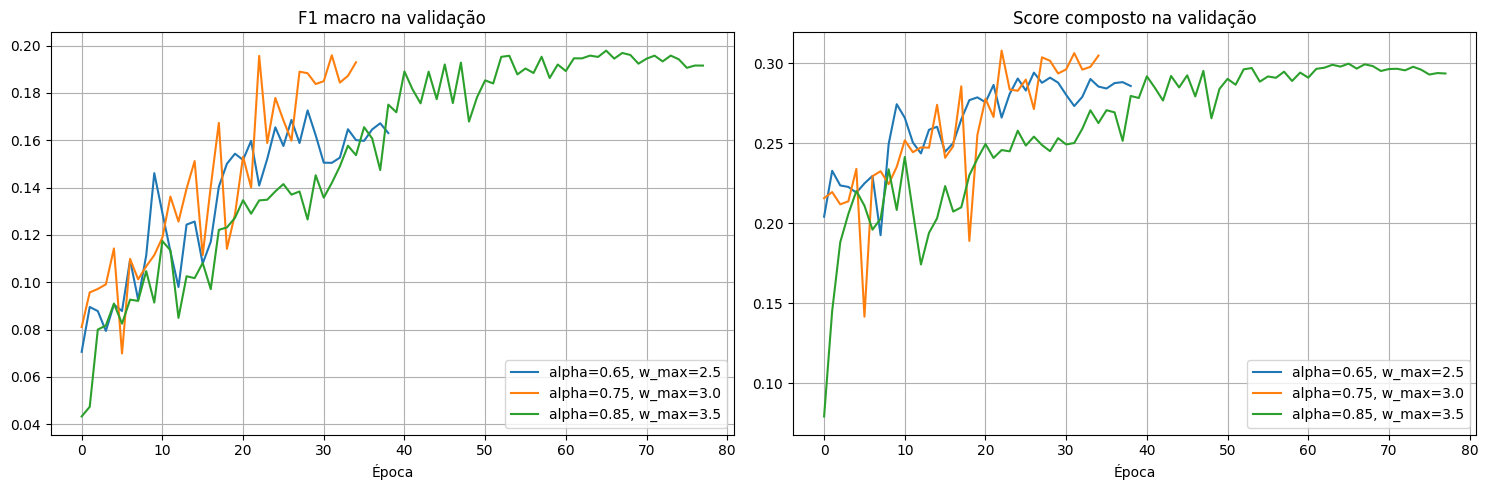

In [8]:
tabela_candidatos = pd.DataFrame([
    {
        'alpha': c['alpha'],
        'w_max': c['w_max'],
        'Épocas': len(c['callback'].score_hist),
        'Melhor época': c['melhor_epoca'],
        'Acurácia': c['metricas_validacao']['acuracia'],
        'Acurácia balanceada': c['metricas_validacao']['acuracia_balanceada'],
        'F1 macro': c['metricas_validacao']['f1_macro'],
        'Score': c['score_validacao'],
        'Recall zero': c['metricas_validacao']['zero_recall'],
        'Tempo (s)': c['tempo'],
    }
    for c in candidatos_resultados
]).sort_values('Score', ascending=False)

display(tabela_candidatos.round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for c in candidatos_resultados:
    label = f"alpha={c['alpha']}, w_max={c['w_max']}"
    axes[0].plot(c['callback'].f1_hist, label=label)
    axes[1].plot(c['callback'].score_hist, label=label)

axes[0].set_title('F1 macro na validação')
axes[1].set_title('Score composto na validação')
for ax in axes:
    ax.set_xlabel('Época')
    ax.legend()
    ax.grid(True)
plt.tight_layout()
plt.show()


In [9]:
melhor = max(candidatos_resultados, key=lambda c: c['score_validacao'])
modelo_final = melhor['modelo']

print('Melhor candidato:', melhor['alpha'], melhor['w_max'])
print('Score na validação:', round(melhor['score_validacao'], 4))

prob_teste = modelo_final.predict(dataset_teste, verbose=0)
metricas_teste_antes = avaliar_previsoes(rotulos_teste, prob_teste)

print('\nTeste antes do ajuste pós-treino:')
for k in ['acuracia', 'acuracia_balanceada', 'precisao_macro', 'recall_macro', 'f1_macro', 'zero_recall']:
    print(f'  {k}: {metricas_teste_antes[k]:.4f}')


Melhor candidato: 0.75 3.0
Score na validação: 0.3078

Teste antes do ajuste pós-treino:
  acuracia: 0.5656
  acuracia_balanceada: 0.2079
  precisao_macro: 0.2061
  recall_macro: 0.2079
  f1_macro: 0.1920
  zero_recall: 5.0000


## 7. Ajuste pós-treino de vieses por classe

Agora ajustamos um viés por classe na validação:

\[
	ext{logits ajustados} = 	ext{logits} + b_c
\]

O ajuste é feito por coordenada: para cada classe, testamos aumentar ou diminuir o viés e mantemos a mudança apenas se o score composto melhorar e a acurácia não cair mais de 1 ponto percentual.

Isso permite corrigir classes que estão sendo previstas demais ou de menos, **sem retreinar**. O teste só é usado depois do ajuste.


**Nota metodológica:** a validação é usada tanto para a busca de pesos quanto para o ajuste de vieses. O teste permanece reservado para a avaliação final. Isso evita usar o teste para escolher hiperparâmetros, mas o ajuste na validação pode ficar otimista; para uma avaliação ainda mais rigorosa, seria necessário um segundo conjunto de validação ou validação cruzada.

In [10]:
def ajustar_vieses(prob_validacao, y_validacao, acc_min, max_rodadas=3):
    logits = np.log(np.clip(prob_validacao, 1e-9, 1.0))
    bias = np.zeros(logits.shape[1], dtype=np.float64)

    def avaliar(b):
        probs = softmax_logits(logits, b)
        m = avaliar_previsoes(y_validacao, probs)
        return score_composto(m), m

    melhor_score, melhor_metricas = avaliar(bias)

    for _ in range(max_rodadas):
        melhorou = False
        for c in range(logits.shape[1]):
            for delta in [-0.5, -0.25, 0.25, 0.5]:
                candidato_bias = bias.copy()
                candidato_bias[c] += delta
                score, metricas = avaliar(candidato_bias)
                if metricas['acuracia'] >= acc_min and score > melhor_score:
                    melhor_score = score
                    melhor_metricas = metricas
                    bias = candidato_bias
                    melhorou = True
        if not melhorou:
            break

    return bias, melhor_metricas

acc_min = melhor['metricas_validacao']['acuracia'] - 0.01
bias_final, metricas_val_ajustadas = ajustar_vieses(
    melhor['prob_validacao'], rotulos_validacao, acc_min
)

print('Viés por classe:')
for classe, b in zip(nomes_das_classes, bias_final):
    if abs(b) > 1e-9:
        print(f'  {classe}: {b:+.2f}')

print('\nValidação antes do ajuste:')
print(melhor['metricas_validacao'])
print('\nValidação depois do ajuste:')
print(metricas_val_ajustadas)

prob_teste_ajustada = softmax_logits(
    np.log(np.clip(prob_teste, 1e-9, 1.0)), bias_final
)
metricas_teste_depois = avaliar_previsoes(rotulos_teste, prob_teste_ajustada)

print('\nTeste depois do ajuste:')
for k in ['acuracia', 'acuracia_balanceada', 'precisao_macro', 'recall_macro', 'f1_macro', 'zero_recall']:
    print(f'  {k}: {metricas_teste_depois[k]:.4f}')


Viés por classe:
  Asio_clamator: -0.25
  Asio_flammeus: -1.25
  Asio_stygius: -1.00
  Bubo_virginianus: -0.25
  Glaucidium_hardyi: +0.50
  Megascops_atricapilla: +0.25
  Megascops_sanctaecatarinae: -0.50
  Pulsatrix_perspicillata: +0.50

Validação antes do ajuste:
{'acuracia': 0.5694214876033058, 'acuracia_balanceada': 0.21673321040486151, 'precisao_macro': 0.21845670444021614, 'recall_macro': 0.21673321040486151, 'f1_macro': 0.1956619562423177, 'zero_recall': 7, 'recall_por_classe': array([0.625     , 0.45652174, 0.13333333, 0.        , 0.85498489,
       0.4       , 0.27184466, 0.        , 0.18181818, 0.        ,
       0.        , 0.09259259, 0.        , 0.        , 0.22222222,
       0.        , 0.1875    , 0.36842105, 0.2       , 0.34042553])}

Validação depois do ajuste:
{'acuracia': 0.6074380165289256, 'acuracia_balanceada': 0.24252035938323258, 'precisao_macro': 0.2413542045405558, 'recall_macro': 0.24252035938323258, 'f1_macro': 0.21688281348917776, 'zero_recall': 6, 'recall_

Relatório por espécie no teste, após o ajuste:
                            precision    recall  f1-score   support

         Aegolius_harrisii      0.375     0.375     0.375         8
             Asio_clamator      0.136     0.191     0.159        47
             Asio_flammeus      0.000     0.000     0.000        14
              Asio_stygius      0.000     0.000     0.000        27
        Athene_cunicularia      0.818     0.906     0.860       663
          Bubo_virginianus      0.206     0.317     0.250        41
    Glaucidium_brasilianum      0.507     0.330     0.400       103
         Glaucidium_hardyi      0.000     0.000     0.000         8
   Glaucidium_minutissimum      0.103     0.273     0.150        11
       Lophostrix_cristata      0.000     0.000     0.000         4
     Megascops_atricapilla      0.000     0.000     0.000         6
         Megascops_choliba      0.265     0.119     0.165       109
Megascops_sanctaecatarinae      0.000     0.000     0.000         8


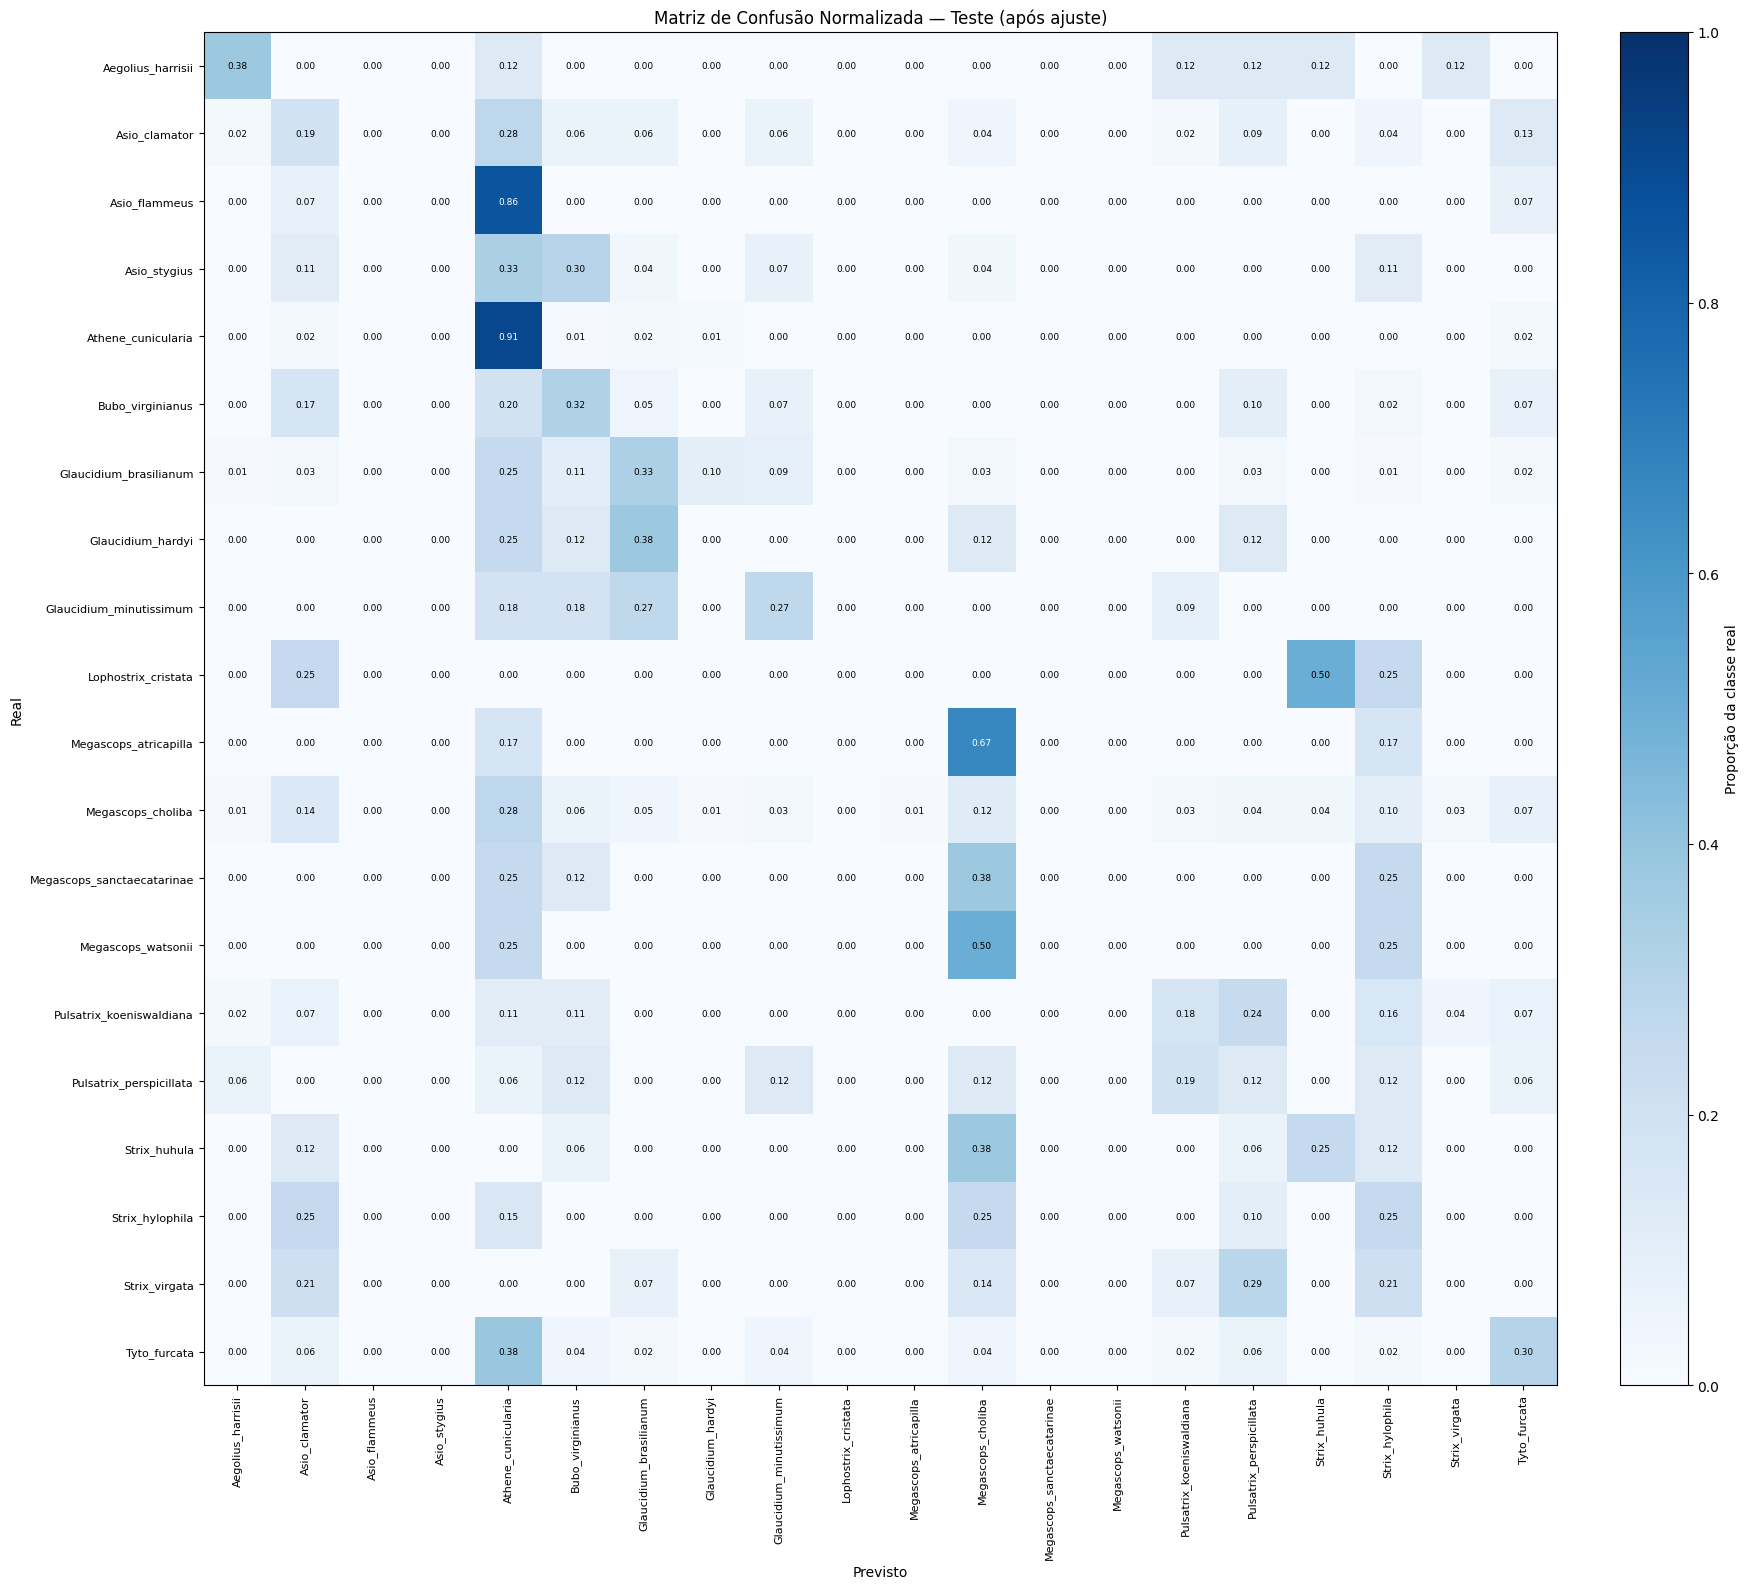

In [11]:
print('Relatório por espécie no teste, após o ajuste:')
print(classification_report(
    rotulos_teste,
    np.argmax(prob_teste_ajustada, axis=1),
    labels=np.arange(num_classes),
    target_names=nomes_das_classes,
    digits=3,
    zero_division=0,
))

cm = confusion_matrix(
    rotulos_teste,
    np.argmax(prob_teste_ajustada, axis=1),
    labels=np.arange(num_classes),
    normalize='true',
)

fig, ax = plt.subplots(figsize=(18, 16))
im = ax.imshow(cm, cmap='Blues', vmin=0, vmax=1)

ax.set_xticks(np.arange(num_classes))
ax.set_yticks(np.arange(num_classes))
ax.set_xticklabels(nomes_das_classes, rotation=90, fontsize=8)
ax.set_yticklabels(nomes_das_classes, fontsize=8)
ax.set_xlabel('Previsto')
ax.set_ylabel('Real')
ax.set_title('Matriz de Confusão Normalizada — Teste (após ajuste)')

for i in range(num_classes):
    for j in range(num_classes):
        valor = cm[i, j]
        ax.text(
            j, i, f'{valor:.2f}',
            ha='center', va='center', fontsize=6.5,
            color='white' if valor > 0.55 else 'black'
        )

cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label('Proporção da classe real')
plt.tight_layout()
plt.show()


,Classe,Suporte no teste,Recall
3,Asio_stygius,27,0.000
2,Asio_flammeus,14,0.000
7,Glaucidium_hardyi,8,0.000
9,Lophostrix_cristata,4,0.000
12,Megascops_sanctaecatarinae,8,0.000
13,Megascops_watsonii,4,0.000
10,Megascops_atricapilla,6,0.000
18,Strix_virgata,14,0.000
11,Megascops_choliba,109,0.119
15,Pulsatrix_perspicillata,16,0.125


Classes com recall zero: ['Asio_stygius', 'Asio_flammeus', 'Glaucidium_hardyi', 'Lophostrix_cristata', 'Megascops_sanctaecatarinae', 'Megascops_watsonii', 'Megascops_atricapilla', 'Strix_virgata']
Classes com recall < 10%: ['Asio_stygius', 'Asio_flammeus', 'Glaucidium_hardyi', 'Lophostrix_cristata', 'Megascops_sanctaecatarinae', 'Megascops_watsonii', 'Megascops_atricapilla', 'Strix_virgata']


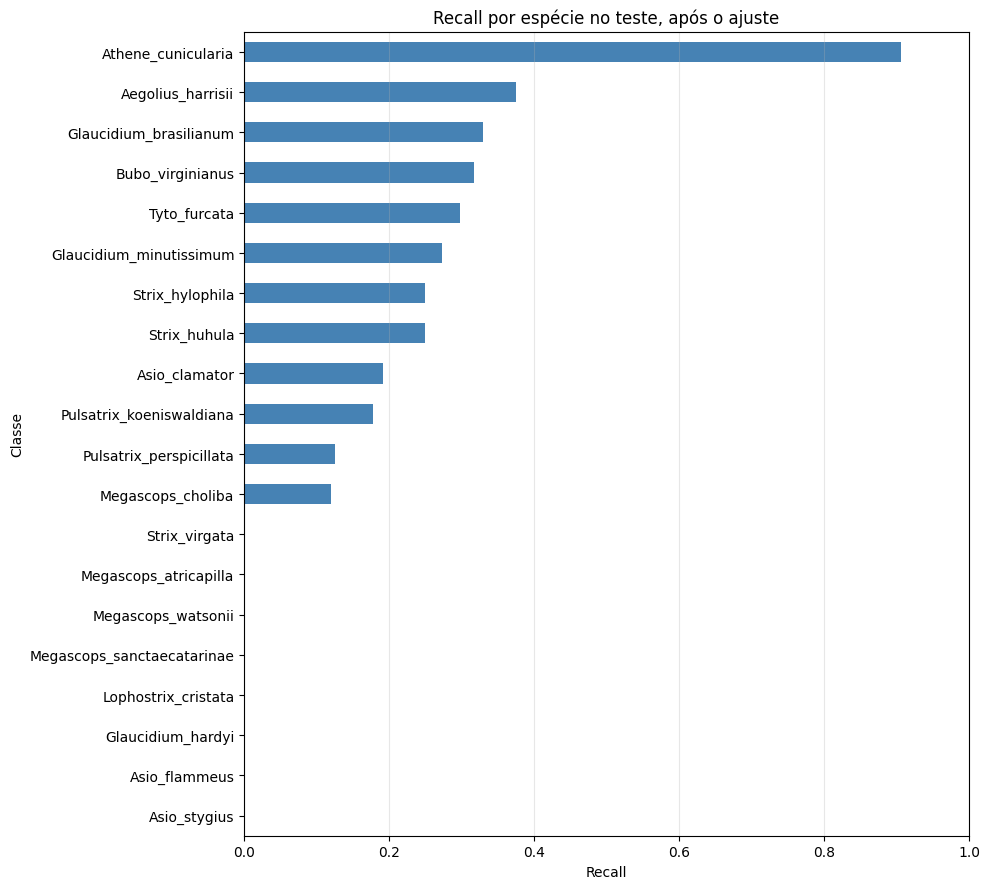

In [12]:
recall_final = metricas_teste_depois['recall_por_classe']
suporte = np.bincount(rotulos_teste, minlength=num_classes)

tabela_recall = pd.DataFrame({
    'Classe': nomes_das_classes,
    'Suporte no teste': suporte,
    'Recall': recall_final,
}).sort_values('Recall')

display(tabela_recall.round(3))

sem_recall = tabela_recall.loc[tabela_recall['Recall'] == 0, 'Classe'].tolist()
baixo_recall = tabela_recall.loc[tabela_recall['Recall'] < 0.10, 'Classe'].tolist()
print('Classes com recall zero:', sem_recall if sem_recall else 'nenhuma')
print('Classes com recall < 10%:', baixo_recall if baixo_recall else 'nenhuma')

tabela_recall.set_index('Classe')['Recall'].plot.barh(
    figsize=(10, 9), color='steelblue'
)
plt.title('Recall por espécie no teste, após o ajuste')
plt.xlabel('Recall')
plt.xlim(0, 1)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()


## 8. Comparação consolidada

A tabela abaixo usa os resultados registrados da V2, V3 e V4 e calcula automaticamente a V5 depois do ajuste pós-treino.


,Versão,Acurácia,Acurácia balanceada,Precisão macro,Recall macro,F1 macro,Classes com recall zero
0,V2,0.6003,0.1338,0.1413,0.1338,0.1266,12
1,V3,0.3146,0.2067,0.1252,0.2067,0.1174,6
2,V4,0.5863,0.2578,0.2382,0.2578,0.2282,3
3,V5,0.5855,0.1806,0.1817,0.1806,0.1708,8


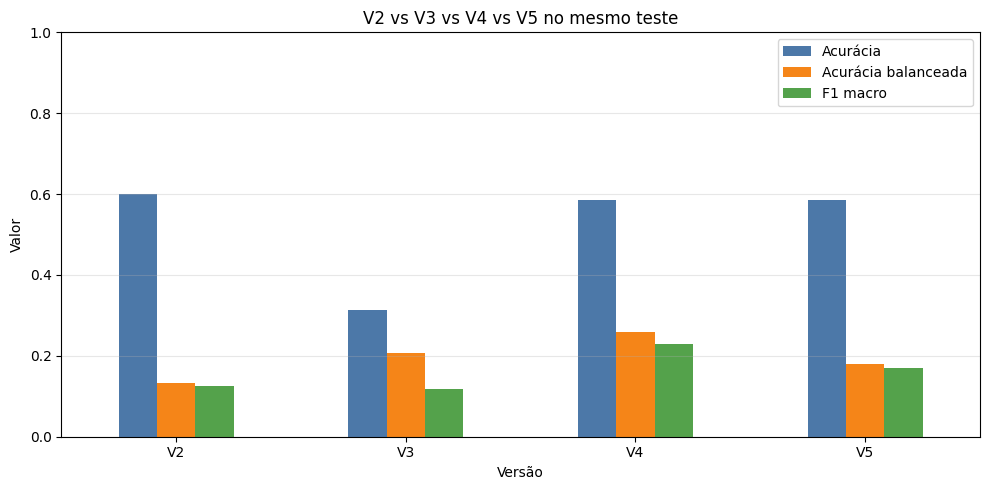

In [13]:
comparativo = pd.DataFrame([
    {
        'Versão': 'V2',
        'Acurácia': 0.6003,
        'Acurácia balanceada': 0.1338,
        'Precisão macro': 0.1413,
        'Recall macro': 0.1338,
        'F1 macro': 0.1266,
        'Classes com recall zero': 12,
    },
    {
        'Versão': 'V3',
        'Acurácia': 0.3146,
        'Acurácia balanceada': 0.2067,
        'Precisão macro': 0.1252,
        'Recall macro': 0.2067,
        'F1 macro': 0.1174,
        'Classes com recall zero': 6,
    },
    {
        'Versão': 'V4',
        'Acurácia': 0.5863,
        'Acurácia balanceada': 0.2578,
        'Precisão macro': 0.2382,
        'Recall macro': 0.2578,
        'F1 macro': 0.2282,
        'Classes com recall zero': 3,
    },
    {
        'Versão': 'V5',
        'Acurácia': metricas_teste_depois['acuracia'],
        'Acurácia balanceada': metricas_teste_depois['acuracia_balanceada'],
        'Precisão macro': metricas_teste_depois['precisao_macro'],
        'Recall macro': metricas_teste_depois['recall_macro'],
        'F1 macro': metricas_teste_depois['f1_macro'],
        'Classes com recall zero': metricas_teste_depois['zero_recall'],
    },
])

display(comparativo.round(4))

comparativo.set_index('Versão')[['Acurácia', 'Acurácia balanceada', 'F1 macro']].plot(
    kind='bar', figsize=(10, 5), rot=0,
    color=['#4C78A8', '#F58518', '#54A24B']
)
plt.title('V2 vs V3 vs V4 vs V5 no mesmo teste')
plt.ylim(0, 1)
plt.ylabel('Valor')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


## 9. Demonstração dentro do Colab

O modelo e o ajuste de vieses ficam na memória da sessão. A célula abaixo é autossuficiente e usa o modelo final já ajustado.


Saving img-2026-11-11-10-59-17.png to img-2026-11-11-10-59-17.png


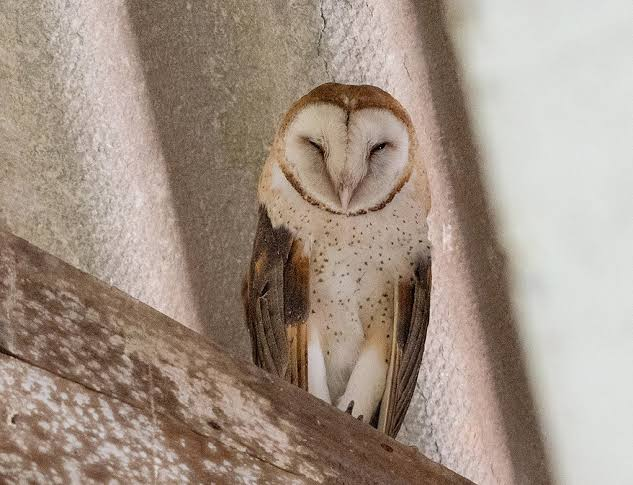

Imagem: img-2026-11-11-10-59-17.png


AxisError: axis 1 is out of bounds for array of dimension 1

In [14]:
from google.colab import files
from PIL import Image, ImageOps
from IPython.display import display
import numpy as np

TAMANHO_PREVISAO = (224, 224)

def softmax_com_vies(logits, bias):
    z = logits + bias
    z = z - np.max(z, axis=1, keepdims=True)
    exp_z = np.exp(z)
    return exp_z / exp_z.sum(axis=1, keepdims=True)

if 'modelo_final' not in globals():
    raise RuntimeError('O modelo final não está na memória desta sessão.')
if 'nomes_das_classes' not in globals():
    raise RuntimeError('A lista de classes não está na memória desta sessão.')
if 'bias_final' not in globals():
    raise RuntimeError('O ajuste de vieses não foi executado.')

def prever(caminho):
    imagem = ImageOps.exif_transpose(Image.open(caminho)).convert('RGB')
    imagem = imagem.resize(TAMANHO_PREVISAO, Image.Resampling.BILINEAR)
    x = np.asarray(imagem, dtype=np.float32)
    probs = modelo_final.predict(x[None, ...], verbose=0)[0]
    probs = softmax_com_vies(np.log(np.clip(probs, 1e-9, 1.0)), bias_final)[0]
    ordem = np.argsort(probs)[-3:][::-1]
    return [(nomes_das_classes[i], float(probs[i])) for i in ordem]

enviados = files.upload()

if not enviados:
    print('Nenhuma imagem foi enviada.')
else:
    for nome in enviados:
        display(Image.open(nome).convert('RGB'))
        print(f'Imagem: {nome}')
        resultados = prever(nome)
        for classe, prob in resultados:
            print(f'  {classe}: {prob:.2%}')
        if resultados[0][1] < 0.5:
            print('  Aviso: confiança baixa; a imagem pode não ser uma das 20 espécies.')


## 10. Conclusão

A V5 separa três decisões que antes ficavam misturadas:

1. **Peso das classes no treino** — escolhido por uma pequena busca automática.
2. **Melhor ponto do treino** — escolhido por score composto na validação.
3. **Fronteira de decisão** — ajustada depois por vieses por classe, também na validação.

O que observar no resultado final:

- **F1 macro** deve aumentar se o ajuste ajudar;
- **acurácia global** não deve cair mais de 1 ponto na validação;
- **recall zero** deve diminuir;
- **precisão macro** mostra se o ganho de recall veio com muitos falsos positivos.

Nada foi salvo no Drive. Se a sessão do Colab for encerrada, o modelo e o ajuste serão perdidos.
